In [3]:
!unzip "/content/train.zip"


Archive:  /content/train.zip
  inflating: train.csv               


In [4]:
import pandas as pd
df = pd.read_csv(
    "/content/train.csv"
)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Exercise 1: Duplicate Detection and Removal


# Step 1: Count duplicate rows
duplicate_count = df.duplicated().sum()

# Step 2: Remove duplicate rows
df = df.drop_duplicates()

# Step 3: Verify that duplicates are removed
print("Duplicates remaining:", df.duplicated().sum())

Duplicates remaining: 0


In [6]:
# Exercise 2: Handling Missing Values

# First lets identify the missing values before we move
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:
# As we see many missing values and we don't want to remove the large chunk of data, lets check the rows we currently have.
df.shape

(891, 12)

In [8]:
# Now lets create a cleaned copy so the original dataset stays safe.
df_clean = df.copy()

In [9]:
df_clean["Age"].median()

28.0

In [10]:
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

In [11]:
# Now that we have identified the missing Age values,
# we will fill them using fillna() and the median.


In [12]:
# Compare missing values before and after filling Age

print("Before the cleaning:")
print(df.isnull().sum())

print("\nAfter the cleaning:")
print(df_clean.isnull().sum())

Before the cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

After the cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [13]:
# Step 2 - Clean Cabin

# Now that we have identified the missing Cabin values,
# we will fill them with "Missing" using fillna().

df_clean["Cabin"] = df_clean["Cabin"].fillna("Missing")



In [14]:

# Check the missing Cabin values after cleaning

print("Cabin missing values before:", df["Cabin"].isnull().sum())
print("Cabin missing values after:", df_clean["Cabin"].isnull().sum())


Cabin missing values before: 687
Cabin missing values after: 0


In [15]:
# We have finish Age and now lets check the result after cleaning and filling Cabin.
df_clean["Cabin"].isnull().sum()

np.int64(0)

In [16]:
# STEP 3: Clean Embarked
# Find the most frequent Embarked value

df_clean["Embarked"].mode()

,Embarked
0,S


In [18]:
# Fill missing Embarked values with the mode

df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

In [17]:
# Checking the result
print("Embarked missing values before:", df["Embarked"].isnull().sum())
print("Embarked missing values after:", df_clean["Embarked"].isnull().sum())

Embarked missing values before: 2
Embarked missing values after: 2


In [19]:
# final verification
# Check missing values after cleaning

df_clean.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [20]:
# Exercise 3: Feature Engineering
# Check the columns we need for Family Size

df_clean[["SibSp", "Parch"]].head()

,SibSp,Parch
0,1,0
1,1,0
2,0,0
3,1,0
4,0,0


In [21]:
# STEP 1: Create a new feature called FamilySize

df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1

In [22]:
# Checking the new feature result
df_clean[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [23]:
# STEP 2: Extract Title from Name
# Chech the Name column

df_clean["Name"].head()

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


In [24]:
# We will extract the title from name eg: Mr Gamuel, we will extract just the Mr.
# We will use Pandas .str.extract() method with a regular expression.

# STEP 2: Extract the passenger's title from the Name column
df_clean["Title"] = df_clean["Name"].str.extract(r", \s*([^.]*)\.")

In [25]:
# Checking the result
df_clean[["Name", "Title"]].head()

,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr


In [26]:
# STEP 3: Check the Titles
#Check the different titles and how often they appear

df_clean["Title"].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [27]:
# STEP 4: One-Hot Encoding
# Convert the Title column into numerical columns using One-Hot Encoding

df_clean = pd.get_dummies(df_clean, columns=["Title"], dtype=int)


In [28]:
# Lets check the result
df_clean.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,0,0,0,0,1,0,0,0,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,0,0,0,0,0,1,0,0,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,0,1,0,0,0,0,0,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,0,0,0,0,0,1,0,0,0,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,0,0,0,0,1,0,0,0,0,0


In [29]:
# Convert Sex and Embarked into numerical columns

df_clean = pd.get_dummies(df_clean, columns=["Sex", "Embarked"], dtype=int)

In [ ]:
# Check which columns are still in our dataset

df_clean.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'FamilySize', 'Title_Capt', 'Title_Col',
       'Title_Don', 'Title_Dr', 'Title_Jonkheer', 'Title_Lady', 'Title_Major',
       'Title_Master', 'Title_Miss', 'Title_Mlle', 'Title_Mme', 'Title_Mr',
       'Title_Mrs', 'Title_Ms', 'Title_Rev', 'Title_Sir', 'Title_the Countess',
       'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S',
       'Title_Capt', 'Title_Col', 'Title_Don', 'Title_Dr', 'Title_Jonkheer',
       'Title_Lady', 'Title_Major', 'Title_Master', 'Title_Miss', 'Title_Mlle',
       'Title_Mme', 'Title_Mr', 'Title_Mrs', 'Title_Ms', 'Title_Rev',
       'Title_Sir', 'Title_the Countess'],
      dtype='object')

In [30]:
# Exercise 4: Outlier Detection and Handling
# Creating a copy before outlier treatment

df_outlier = df_clean.copy()


In [33]:
# Visualize potential outliers in Age and Fare
import matplotlib.pyplot as plt


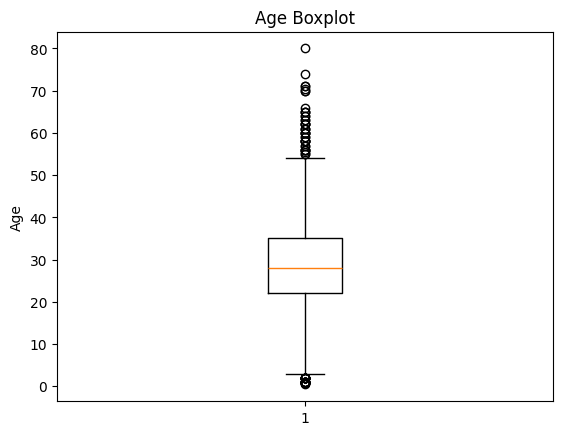

In [34]:
# Create a boxplot for Age

plt.boxplot(df_outlier["Age"])
plt.title("Age Boxplot")
plt.ylabel("Age")
plt.show()

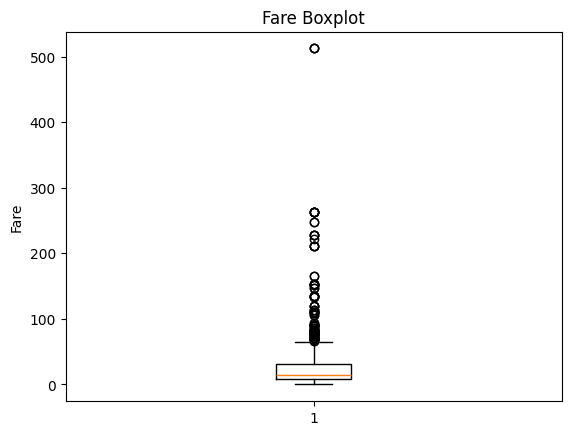

In [35]:
# Create a boxplot for Fare

plt.boxplot(df_outlier["Fare"])
plt.title("Fare Boxplot")
plt.ylabel("Fare")
plt.show()

In [36]:
# Since we got outlier which is not very accurate so we will investigate in depth.

# Calculate Q1, Q3 and IQR for Fare
Q1 = df_outlier["Fare"].quantile(0.25)
Q3 = df_outlier["Fare"].quantile(0.75)

IQR = Q3- Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 7.9104
Q3: 31.0
IQR: 23.0896


In [37]:
# Calculate the outlier boundaries for Fare
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -26.724
Upper limit: 65.6344


In [38]:
# Count Fare values above the upper outlier limit
fare_outliers = df_outlier[df_outlier["Fare"] > upper_limit]
print("Number of Fare outliers:", len(fare_outliers))

Number of Fare outliers: 116


In [39]:
# Find the 98th percentile of Fare

fare_98 = df_outlier["Fare"].quantile(0.98)
print("Fare 98th percentile:", fare_98)

Fare 98th percentile: 211.3375


In [40]:
# Find the 99th percentile of Fare
fare_99 = df_outlier["Fare"].quantile(0.99)
print("Fare 99th percentile:", fare_99)

Fare 99th percentile: 249.00622000000035


In [41]:
# Cap Fare at the 98th percentile

fare_98 = df_outlier["Fare"].quantile(0.98)
df_outlier["Fare_capped"] = df_outlier["Fare"].clip(upper=fare_98)

In [42]:
# Checking the maximum before and after
print("Maximum Fare before:", df_outlier["Fare"].max())
print("Maximum Fare after:", df_outlier["Fare_capped"].max())

Maximum Fare before: 512.3292
Maximum Fare after: 211.3375


In [43]:
# Compare Fare before and after

print("Fare before caping:")
print(df_outlier["Fare"].describe())

print("\nFare after caping")
print(df_outlier["Fare_capped"].describe())

Fare before caping:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

Fare after caping
count    891.000000
mean      30.678483
std       39.904946
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      211.337500
Name: Fare_capped, dtype: float64


In [44]:
# Calculate the Age IQR

Q1_age = df_outlier["Age"].quantile(0.25)
Q3_age = df_outlier["Age"].quantile(0.75)

IQR_age = Q3_age - Q1_age

print("Q1:", Q1_age)
print("Q2:", Q3_age)
print("IQR:", IQR_age)

Q1: 22.0
Q2: 35.0
IQR: 13.0


In [46]:
# Calculate the Age outlier limits
lower_limit_age = Q1_age - 1.5 * IQR_age
upper_limit_age = Q3_age + 1.5 * IQR_age

print("Lower limit:", lower_limit_age)
print("Upper limit:", upper_limit_age)

Lower limit: 2.5
Upper limit: 54.5


In [47]:
# Count Age outliers

age_outliers = df_outlier[
    (df_outlier["Age"] < lower_limit_age) |
    (df_outlier["Age"] > upper_limit_age)
]
print("Number of Age outliers:", len(age_outliers))

Number of Age outliers: 66


In [48]:
# Cap age at the 98th percentile

age_98 = df_outlier["Age"].quantile(0.98)
print("98th percentile:", age_98)

98th percentile: 62.0


In [49]:
# Compare the maximum

# First lets make a new Age_capped and change value above 62 become 62
df_outlier["Age_capped"] = df_outlier["Age"].clip(upper=age_98)

print("Maximum Age before:", df_outlier["Age"].max())
print("Maximum Age after:", df_outlier["Age_capped"].max())


Maximum Age before: 80.0
Maximum Age after: 62.0


In [50]:
# Compare Age before and after

print("Age before capping:")
print(df_outlier["Age"].describe())

print("\nAge after capping:")
print(df_outlier["Age_capped"].describe())

Age before capping:
count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

Age after capping:
count    891.000000
mean      29.258889
std       12.720003
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       62.000000
Name: Age_capped, dtype: float64


### Outlier Detection and Handling

I used the IQR method to detect potential outliers in the Fare and Age columns.

For Fare, the IQR upper limit was 65.6344, and 116 potential outliers were identified. I capped values above the 98th percentile (211.3375). After capping, the maximum Fare decreased from 512.3292 to 211.3375.

For Age, the IQR lower limit was 2.5 and the upper limit was 54.5. I identified 66 potential outliers and capped values above the 98th percentile (62.0). The maximum Age decreased from 80 to 62.

After capping both columns, the number of rows remained 891. The mean and standard deviation decreased, while the median remained unchanged.

This process reduced the influence of extreme values while preserving the original number of observations.

In [55]:
# Exercise 5: Data Standardization and Normalization

# Import MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

# Create a copy of the dataset
df_scaled = df_outlier.copy()

# Select numerical features to scale
columns = ["Age_capped", "Fare_capped", "SibSp", "Parch", "FamilySize"]

# Create the scaler
scaler = MinMaxScaler()

# Scale selected columns to a range of 0 to 1
df_scaled[columns] = scaler.fit_transform(df_scaled[columns])


In [56]:
# Exercise 6: Feature Encoding

# Identifying remaining categorical columns
categorical_coloums = df_scaled.select_dtypes(include="object").columns

# Apply One - Hot Encoding to nominal categorical columns
df_scaled = pd.get_dummies(
    df_scaled,
    columns=categorical_coloums,
    dtype=int
)

In our titanic dataset, Pclass is already represented by numbers 1,2 and 3, so we don't need to apply Label Encoding to it.

In [57]:
# Check if any categorical columns remain
print(df_scaled.select_dtypes(include="object").columns)

Index([], dtype='object')


In [58]:
# Exercise 7: Data Transformation for Age Feature

# Create a copy of the dataset
df_age = df_outlier.copy()

# Create age groups using pd.cut()
df_age["AgeGroup"] = pd.cut(
    df_age["Age_capped"],
    bins=[0, 12, 18, 60, 100],
    labels=["Child", "Teen", "Adult", "Senior"],
    include_lowest=True
)

# One-hot encode the age groups
df_age = pd.get_dummies(
    df_age,
    columns=["AgeGroup"],
    dtype=int
)

# Important to understand this parts
pd.cut() = divides Age into groups.

bins defines the age boundaries.

labels gives each group a name.

include_lowest = True includes age 0 in the first group.

pd.get_dummies() converts the age groups into 0/1 columns.

In [59]:
# Display the new age-group columns
df_age.filter(like="AgeGroup").head()

,AgeGroup_Child,AgeGroup_Teen,AgeGroup_Adult,AgeGroup_Senior
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0
